# DEPI Mini-Project 2 — Advanced SQL Data Warehouse & Business Analytics
### ETL Pipeline: Excel → Pandas → SQL Server, and SQL-Server-Driven Business Analysis

**Dataset:** `Central_Superstore.xlsx` (Central Region, 2,323 order-line records)
**Target database:** `DEPI_Superstore_DW` (Microsoft SQL Server)

**Workflow of this notebook:**
1. Load & inspect the raw Excel data
2. Clean the data and document every cleaning decision
3. Build the Star Schema dimension & fact DataFrames
4. Connect to SQL Server with SQLAlchemy + pyodbc
5. Load (insert) the dimension/fact DataFrames into SQL Server
6. Verify loaded row counts
7. Query SQL Server **from Python** with `pd.read_sql()` and analyze the results
8. Produce charts (Monthly Sales Trend, Sales by Category, Profit by Category, Top 10 Customers, Sales vs Profit)

> **Before running Section 4 onward**, make sure SQL Server is running and you
> have already executed `sql/01_create_database.sql` and
> `sql/02_create_star_schema.sql` in SSMS (or let this notebook create the
> tables — the DataFrames it builds match the schema exactly).


## 1. Imports

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus
import pyodbc

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries imported successfully.")
print("pandas:", pd.__version__)


Libraries imported successfully.
pandas: 2.3.3


## 2. Load and Inspect the Raw Dataset

We load the single sheet (`Central_Region`) from `Central_Superstore.xlsx` and
inspect its shape, columns, data types, missing values, duplicates, and a
sample of records — as required before any schema design.

In [33]:
SOURCE_FILE = '../data/Central_Superstore.xlsx'

df_raw = pd.read_excel(SOURCE_FILE, sheet_name='Central_Region')

print("Number of rows   :", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])
print("\nColumn names:")
print(list(df_raw.columns))


Number of rows   : 2323
Number of columns: 21

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [34]:
print("Data types:\n")
print(df_raw.dtypes)


Data types:

Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [35]:
print("Missing values per column:\n")
print(df_raw.isnull().sum())
print("\nTotal missing values:", df_raw.isnull().sum().sum())


Missing values per column:

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Total missing values: 0


In [36]:
print("Fully duplicated rows:", df_raw.duplicated().sum())
print("Duplicate Row ID values:", df_raw['Row ID'].duplicated().sum())


Fully duplicated rows: 0
Duplicate Row ID values: 0


In [37]:
df_raw.head(5)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,15,US-2012-118983,2014-11-22,2014-11-26,Standard Class,HP-14815,Harold Pawlan,Home Office,United States,Fort Worth,Texas,76106,Central,OFF-AP-10002311,Office Supplies,Appliances,Holmes Replacement Filter for HEPA Air Cleaner...,68.810,5,0.8,-123.8580
1,16,US-2012-118983,2014-11-22,2014-11-26,Standard Class,HP-14815,Harold Pawlan,Home Office,United States,Fort Worth,Texas,76106,Central,OFF-BI-10000756,Office Supplies,Binders,Storex DuraTech Recycled Plastic Frosted Binders,2.544,3,0.8,-3.8160
2,17,CA-2011-105893,2013-11-11,2013-11-18,Standard Class,PK-19075,Pete Kriz,Consumer,United States,Madison,Wisconsin,53711,Central,OFF-ST-10004186,Office Supplies,Storage,"Stur-D-Stor Shelving, Vertical 5-Shelf: 72""H x...",665.880,6,0.0,13.3176
3,22,CA-2013-137330,2015-12-10,2015-12-14,Standard Class,KB-16585,Ken Black,Corporate,United States,Fremont,Nebraska,68025,Central,OFF-AR-10000246,Office Supplies,Art,Newell 318,19.460,7,0.0,5.0596
4,23,CA-2013-137330,2015-12-10,2015-12-14,Standard Class,KB-16585,Ken Black,Corporate,United States,Fremont,Nebraska,68025,Central,OFF-AP-10001492,Office Supplies,Appliances,"Acco Six-Outlet Power Strip, 4' Cord Length",60.340,7,0.0,15.6884


In [38]:
df_raw[['Sales', 'Quantity', 'Discount', 'Profit']].describe()


,Sales,Quantity,Discount,Profit
count,2323.000000,2323.000000,2323.000000,2323.000000
mean,215.772661,3.779595,0.240353,17.092709
std,632.779010,2.160561,0.265433,291.487465
min,0.444000,1.000000,0.000000,-3701.892800
25%,14.620000,2.000000,0.000000,-5.664300
50%,45.980000,3.000000,0.200000,5.184000
75%,200.012000,5.000000,0.300000,22.456200
max,17499.950000,14.000000,0.800000,8399.976000


### 2.1 Identify column types and candidate keys

- **Categorical columns:** `Ship Mode`, `Segment`, `Country`, `City`, `State`, `Region`, `Category`, `Sub-Category`
- **Numeric (measure) columns:** `Sales`, `Quantity`, `Discount`, `Profit`
- **Date columns:** `Order Date`, `Ship Date`
- **Candidate business/natural keys:** `Row ID` (unique per order line), `Order ID` (shared across multiple line items of the same order), `Customer ID`, `Product ID`


In [39]:
for col in ['Ship Mode', 'Segment', 'Country', 'Region', 'Category']:
    print(f"{col}: {df_raw[col].unique()}")

print("\nDate ranges:")
print("Order Date:", df_raw['Order Date'].min(), "to", df_raw['Order Date'].max())
print("Ship Date :", df_raw['Ship Date'].min(), "to", df_raw['Ship Date'].max())


Ship Mode: ['Standard Class' 'Second Class' 'First Class' 'Same Day']
Segment: ['Home Office' 'Consumer' 'Corporate']
Country: ['United States']
Region: ['Central']
Category: ['Office Supplies' 'Technology' 'Furniture']

Date ranges:
Order Date: 2013-01-03 00:00:00 to 2016-12-30 00:00:00
Ship Date : 2013-01-07 00:00:00 to 2017-01-05 00:00:00


### 2.2 Data Quality Findings

Inspection of the raw file revealed the following:

| # | Finding | Decision |
|---|---------|----------|
| 1 | No missing values in any column | No imputation needed |
| 2 | No fully duplicated rows, `Row ID` is unique | `Row ID` used as the fact-table business key / grain |
| 3 | **16 `Product ID` values appear with 2 different `Product Name` values** each (the same product code was reused for a different item in the source system) | Kept **one name per `Product ID`** (the first one that appears), so `DimProduct` has exactly one row per product |
| 4 | 4 `Product Name` values have leading/trailing whitespace | Trimmed all string columns |
| 5 | 4 `City`/`State` combinations map to more than one `Postal Code` | `DimGeography` is built on the full combination of City + State + PostalCode + Region + Country, not City/State alone |
| 6 | `Ship Date` is always on/after `Order Date` | Validated with an assertion, no rows violate this |

No columns were invented; every column in the star schema traces back to an original column in `Central_Superstore.xlsx`, except the surrogate integer keys and the derived `DateKey`/calendar attributes in `DimDate`.


## 3. Data Cleaning

Applying the cleaning decisions documented above.

In [40]:
df = df_raw.copy()

# Standardize column names (defensive - strip whitespace from headers)
df.columns = [c.strip() for c in df.columns]

# Trim whitespace from all string columns
str_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
for c in str_cols:
    df[c] = df[c].astype(str).str.strip()

# Drop exact duplicate rows (defensive - none expected)
before_rows = len(df)
df = df.drop_duplicates()
print(f"Dropped {before_rows - len(df)} exact duplicate rows.")

# Row ID must be unique - this is our fact-table grain
assert df['Row ID'].is_unique, "Row ID is not unique - cannot use as fact grain!"
print("Row ID uniqueness verified:", df['Row ID'].is_unique)


Dropped 0 exact duplicate rows.
Row ID uniqueness verified: True


In [41]:
# Some Product IDs appear with two different Product Names in the source file.
# We keep ONE name per Product ID so that DimProduct has exactly one row per
# product. We keep the first name that appears for each Product ID.
conflicts = (df.groupby('Product ID')['Product Name'].nunique() > 1).sum()
print("Product IDs that had more than one name:", conflicts)

# Build a lookup of one name per Product ID, then apply it to every row
name_lookup = df[['Product ID', 'Product Name']].drop_duplicates(subset='Product ID')
df = df.drop(columns='Product Name').merge(name_lookup, on='Product ID', how='left')

print("Each Product ID now has one name:", (df.groupby('Product ID')['Product Name'].nunique() == 1).all())


Product IDs that had more than one name: 16
Each Product ID now has one name: True


In [42]:
# Validate numeric ranges and date logic
assert (df['Quantity'] > 0).all(), "Found non-positive Quantity values"
assert (df['Discount'] >= 0).all() and (df['Discount'] <= 1).all(), "Discount out of [0,1] range"
assert (df['Ship Date'] >= df['Order Date']).all(), "Found Ship Date earlier than Order Date"

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Final cleaned shape:", df.shape)
df.head(3)


Missing values after cleaning: 0
Final cleaned shape: (2323, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Sales,Quantity,Discount,Profit,Product Name
0,15,US-2012-118983,2014-11-22,2014-11-26,Standard Class,HP-14815,Harold Pawlan,Home Office,United States,Fort Worth,Texas,76106,Central,OFF-AP-10002311,Office Supplies,Appliances,68.810,5,0.8,-123.8580,Holmes Replacement Filter for HEPA Air Cleaner...
1,16,US-2012-118983,2014-11-22,2014-11-26,Standard Class,HP-14815,Harold Pawlan,Home Office,United States,Fort Worth,Texas,76106,Central,OFF-BI-10000756,Office Supplies,Binders,2.544,3,0.8,-3.8160,Storex DuraTech Recycled Plastic Frosted Binders
2,17,CA-2011-105893,2013-11-11,2013-11-18,Standard Class,PK-19075,Pete Kriz,Consumer,United States,Madison,Wisconsin,53711,Central,OFF-ST-10004186,Office Supplies,Storage,665.880,6,0.0,13.3176,"Stur-D-Stor Shelving, Vertical 5-Shelf: 72""H x..."


In [43]:
# Save the cleaned flat file (used as an intermediate artifact / audit trail)
df.to_csv('../data/cleaned_superstore.csv', index=False)
print("Saved cleaned dataset to data/cleaned_superstore.csv")


Saved cleaned dataset to data/cleaned_superstore.csv


## 4. Build the Star Schema DataFrames

We now build one DataFrame per dimension table and the fact table, matching
`sql/02_create_star_schema.sql` exactly:

- `DimDate` — calendar dimension (role-playing: reused for both Order Date and Ship Date)
- `DimCustomer` — one row per unique `Customer ID`
- `DimProduct` — one row per unique `Product ID`
- `DimGeography` — one row per unique City/State/PostalCode/Region/Country combination
- `DimShipMode` — one row per shipping mode
- `FactSales` — one row per order line (`Row ID`), with foreign keys to every dimension plus the measures `Sales`, `Quantity`, `Discount`, `Profit`


In [44]:
# ---- DimDate ----
all_dates = pd.Series(pd.concat([df['Order Date'], df['Ship Date']]).unique()).sort_values().reset_index(drop=True)
dim_date = pd.DataFrame({'FullDate': all_dates})
dim_date['DateKey']     = dim_date['FullDate'].dt.strftime('%Y%m%d').astype(int)
dim_date['Day']         = dim_date['FullDate'].dt.day
dim_date['Month']       = dim_date['FullDate'].dt.month
dim_date['MonthName']   = dim_date['FullDate'].dt.strftime('%B')
dim_date['Quarter']     = dim_date['FullDate'].dt.quarter
dim_date['Year']        = dim_date['FullDate'].dt.year
dim_date['Weekday']     = dim_date['FullDate'].dt.weekday + 1
dim_date['WeekdayName'] = dim_date['FullDate'].dt.strftime('%A')
dim_date = dim_date[['DateKey','FullDate','Day','Month','MonthName','Quarter','Year','Weekday','WeekdayName']]

print("DimDate:", dim_date.shape)
dim_date.head(3)


DimDate: (1058, 9)


,DateKey,FullDate,Day,Month,MonthName,Quarter,Year,Weekday,WeekdayName
0,20130103,2013-01-03,3,1,January,1,2013,4,Thursday
1,20130104,2013-01-04,4,1,January,1,2013,5,Friday
2,20130107,2013-01-07,7,1,January,1,2013,1,Monday


In [45]:
# ---- DimCustomer ----
dim_customer = df[['Customer ID','Customer Name','Segment']].drop_duplicates().reset_index(drop=True)
dim_customer.insert(0, 'CustomerKey', range(1, len(dim_customer) + 1))
dim_customer = dim_customer.rename(columns={'Customer ID':'CustomerID','Customer Name':'CustomerName'})

assert dim_customer['CustomerID'].is_unique
print("DimCustomer:", dim_customer.shape)
dim_customer.head(3)


DimCustomer: (629, 4)


,CustomerKey,CustomerID,CustomerName,Segment
0,1,HP-14815,Harold Pawlan,Home Office
1,2,PK-19075,Pete Kriz,Consumer
2,3,KB-16585,Ken Black,Corporate


In [46]:
# ---- DimProduct ----
dim_product = df[['Product ID','Product Name','Category','Sub-Category']].drop_duplicates().reset_index(drop=True)
dim_product.insert(0, 'ProductKey', range(1, len(dim_product) + 1))
dim_product = dim_product.rename(columns={'Product ID':'ProductID','Product Name':'ProductName','Sub-Category':'SubCategory'})

assert dim_product['ProductID'].is_unique
print("DimProduct:", dim_product.shape)
dim_product.head(3)


DimProduct: (1310, 5)


,ProductKey,ProductID,ProductName,Category,SubCategory
0,1,OFF-AP-10002311,Holmes Replacement Filter for HEPA Air Cleaner...,Office Supplies,Appliances
1,2,OFF-BI-10000756,Storex DuraTech Recycled Plastic Frosted Binders,Office Supplies,Binders
2,3,OFF-ST-10004186,"Stur-D-Stor Shelving, Vertical 5-Shelf: 72""H x...",Office Supplies,Storage


In [47]:
# ---- DimGeography ----
dim_geo = df[['City','State','Postal Code','Region','Country']].drop_duplicates().reset_index(drop=True)
dim_geo.insert(0, 'GeographyKey', range(1, len(dim_geo) + 1))
dim_geo = dim_geo.rename(columns={'Postal Code':'PostalCode'})

print("DimGeography:", dim_geo.shape)
dim_geo.head(3)


DimGeography: (195, 6)


,GeographyKey,City,State,PostalCode,Region,Country
0,1,Fort Worth,Texas,76106,Central,United States
1,2,Madison,Wisconsin,53711,Central,United States
2,3,Fremont,Nebraska,68025,Central,United States


In [48]:
# ---- DimShipMode ----
dim_shipmode = df[['Ship Mode']].drop_duplicates().reset_index(drop=True)
dim_shipmode.insert(0, 'ShipModeKey', range(1, len(dim_shipmode) + 1))
dim_shipmode = dim_shipmode.rename(columns={'Ship Mode':'ShipMode'})

print("DimShipMode:", dim_shipmode.shape)
dim_shipmode


DimShipMode: (4, 2)


,ShipModeKey,ShipMode
0,1,Standard Class
1,2,Second Class
2,3,First Class
3,4,Same Day


In [49]:
# ---- FactSales ----
fact = df.merge(dim_customer[['CustomerKey','CustomerID']], left_on='Customer ID', right_on='CustomerID', how='left')
fact = fact.merge(dim_product[['ProductKey','ProductID']], left_on='Product ID', right_on='ProductID', how='left')
fact = fact.merge(
    dim_geo[['GeographyKey','City','State','PostalCode','Region','Country']],
    left_on=['City','State','Postal Code','Region','Country'],
    right_on=['City','State','PostalCode','Region','Country'],
    how='left'
)
fact = fact.merge(dim_shipmode, left_on='Ship Mode', right_on='ShipMode', how='left')
fact = fact.merge(
    dim_date[['DateKey','FullDate']].rename(columns={'DateKey':'OrderDateKey','FullDate':'Order Date'}),
    on='Order Date', how='left'
)
fact = fact.merge(
    dim_date[['DateKey','FullDate']].rename(columns={'DateKey':'ShipDateKey','FullDate':'Ship Date'}),
    on='Ship Date', how='left'
)

fact_sales = fact[['Row ID','Order ID','CustomerKey','ProductKey','GeographyKey','ShipModeKey',
                    'OrderDateKey','ShipDateKey','Sales','Quantity','Discount','Profit']].copy()
fact_sales = fact_sales.rename(columns={'Row ID':'RowID','Order ID':'OrderID'})
fact_sales.insert(0, 'SalesKey', range(1, len(fact_sales) + 1))

print("FactSales:", fact_sales.shape)
print("\nNull check (should all be 0):")
print(fact_sales.isnull().sum())
fact_sales.head(3)


FactSales: (2323, 13)

Null check (should all be 0):
SalesKey        0
RowID           0
OrderID         0
CustomerKey     0
ProductKey      0
GeographyKey    0
ShipModeKey     0
OrderDateKey    0
ShipDateKey     0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64


,SalesKey,RowID,OrderID,CustomerKey,ProductKey,GeographyKey,ShipModeKey,OrderDateKey,ShipDateKey,Sales,Quantity,Discount,Profit
0,1,15,US-2012-118983,1,1,1,1,20141122,20141126,68.810,5,0.8,-123.8580
1,2,16,US-2012-118983,1,2,1,1,20141122,20141126,2.544,3,0.8,-3.8160
2,3,17,CA-2011-105893,2,3,2,1,20131111,20131118,665.880,6,0.0,13.3176


In [50]:
# ---- ETL Validation: confirm zero business-measure loss before loading to SQL Server ----
print("Original Total Sales :", round(df['Sales'].sum(), 2))
print("FactSales Total Sales:", round(fact_sales['Sales'].sum(), 2))
print("Original Total Profit :", round(df['Profit'].sum(), 2))
print("FactSales Total Profit:", round(fact_sales['Profit'].sum(), 2))

assert abs(df['Sales'].sum() - fact_sales['Sales'].sum()) < 0.01
assert abs(df['Profit'].sum() - fact_sales['Profit'].sum()) < 0.01
print("\nValidation passed: no Sales/Profit lost while building the star schema.")


Original Total Sales : 501239.89
FactSales Total Sales: 501239.89
Original Total Profit : 39706.36
FactSales Total Profit: 39706.36

Validation passed: no Sales/Profit lost while building the star schema.


## 5. Connect Jupyter to SQL Server

Using SQLAlchemy + pyodbc to connect to the `DEPI_Superstore_DW` database created by `sql/01_create_database.sql`.

Server name (from `SELECT @@SERVERNAME;` in SSMS): `Fatima_Awad`


In [65]:
# Change SERVER_NAME to your own SQL Server instance (run SELECT @@SERVERNAME; in SSMS)
SERVER_NAME = "Fatima_Awad"
DATABASE_NAME = "DEPI_Superstore_DW"

connection_string = quote_plus(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={SERVER_NAME};"
    f"DATABASE={DATABASE_NAME};"
    "Trusted_Connection=yes;"
)

engine = create_engine(f"mssql+pyodbc:///?odbc_connect={connection_string}")

print("Connected to", DATABASE_NAME, "on", SERVER_NAME)


Connected to DEPI_Superstore_DW on Fatima_Awad


In [66]:
# Test the connection
try:
    with engine.connect() as conn:
        result = conn.execute(text("SELECT @@VERSION AS SqlServerVersion;"))
        for row in result:
            print("Connected successfully. SQL Server version:")
            print(row.SqlServerVersion)
except Exception as e:
    print("Connection failed. See the troubleshooting section below.")
    print("Error:", e)


Connected successfully. SQL Server version:
Microsoft SQL Server 2025 (RTM) - 17.0.1000.7 (X64) 
	Oct 21 2025 12:05:57 
	Copyright (C) 2025 Microsoft Corporation
	Standard Developer Edition (64-bit) on Windows 10 Pro 10.0 <X64> (Build 26200: ) (Hypervisor)



C:\Users\Fatima Awad\AppData\Local\Temp\ipykernel_3208\122869806.py:3: SAWarning: Unrecognized server version info '17.0.1000.7'.  Some SQL Server features may not function properly.
  with engine.connect() as conn:


## 6. Load the Star Schema DataFrames into SQL Server

Each DataFrame is written to its matching table using `to_sql()` with
`if_exists='append'`, because the tables (with primary keys, foreign keys,
and constraints) are already created by `sql/02_create_star_schema.sql`.
Loading dimensions first is required so the fact table's foreign keys are
valid when it loads.

> Run `sql/01_create_database.sql` and `sql/02_create_star_schema.sql` in
> SSMS before running this cell.


In [67]:
# Load order matters: dimensions first, fact table last (FK dependency)
tables_to_load = [
    ("DimDate", dim_date),
    ("DimCustomer", dim_customer),
    ("DimProduct", dim_product),
    ("DimGeography", dim_geo),
    ("DimShipMode", dim_shipmode),
    ("FactSales", fact_sales),
]

try:
    for table_name, dataframe in tables_to_load:
        dataframe.to_sql(table_name, con=engine, if_exists='append', index=False)
        print(f"Loaded {len(dataframe):>5} rows into dbo.{table_name}")
    print("\nAll tables loaded successfully.")
except Exception as e:
    print("Load failed. Make sure sql/01_create_database.sql and")
    print("sql/02_create_star_schema.sql have been run in SSMS first.")
    print("Error:", e)


Load failed. Make sure sql/01_create_database.sql and
sql/02_create_star_schema.sql have been run in SSMS first.
Error: (pyodbc.IntegrityError) ('23000', "[23000] [Microsoft][ODBC Driver 17 for SQL Server][SQL Server]Violation of PRIMARY KEY constraint 'PK_DimDate'. Cannot insert duplicate key in object 'dbo.DimDate'. The duplicate key value is (20130103). (2627) (SQLExecDirectW); [23000] [Microsoft][ODBC Driver 17 for SQL Server][SQL Server]The statement has been terminated. (3621)")
[SQL: INSERT INTO [DimDate] ([DateKey], [FullDate], [Day], [Month], [MonthName], [Quarter], [Year], [Weekday], [WeekdayName]) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?), (?, ?, ?, ?, ?, ?, ?, ?, ?), (?, ?, ?, ?, ?, ?, ?, ?, ?), (?, ?, ?, ?, ?, ?, ?, ?, ?), (?, ?,  ... 6532 characters truncated ... , ?, ?, ?, ?), (?, ?, ?, ?, ?, ?, ?, ?, ?), (?, ?, ?, ?, ?, ?, ?, ?, ?), (?, ?, ?, ?, ?, ?, ?, ?, ?)]
[parameters: (20130103, datetime.datetime(2013, 1, 3, 0, 0), 3, 1, 'January', 1, 2013, 4, 'Thursday', 20130104, datet

In [68]:
# Verify loaded row counts directly from SQL Server
verify_query = """
SELECT 'DimDate' AS TableName, COUNT(*) AS TotalRows FROM DimDate
UNION ALL SELECT 'DimCustomer', COUNT(*) FROM DimCustomer
UNION ALL SELECT 'DimProduct', COUNT(*) FROM DimProduct
UNION ALL SELECT 'DimGeography', COUNT(*) FROM DimGeography
UNION ALL SELECT 'DimShipMode', COUNT(*) FROM DimShipMode
UNION ALL SELECT 'FactSales', COUNT(*) FROM FactSales;
"""

df_counts = pd.read_sql(verify_query, engine)
df_counts


,TableName,TotalRows
0,DimDate,1058
1,DimCustomer,629
2,DimProduct,1310
3,DimGeography,195
4,DimShipMode,4
5,FactSales,2323


## 7. Business Analysis — Querying SQL Server FROM Python

From this point on, all analysis reads data **back out of SQL Server** with
`pd.read_sql()`, demonstrating a genuine Jupyter ↔ SQL Server round trip
(not just re-analyzing the original Excel file in memory).


In [69]:
sales_query = """
SELECT
    d.[Year],
    d.[Month],
    d.MonthName,
    SUM(f.Sales)  AS TotalSales,
    SUM(f.Profit) AS TotalProfit
FROM FactSales AS f
JOIN DimDate AS d ON f.OrderDateKey = d.DateKey
GROUP BY d.[Year], d.[Month], d.MonthName
ORDER BY d.[Year], d.[Month];
"""

df_monthly = pd.read_sql(sales_query, engine)
df_monthly.head(10)


,Year,Month,MonthName,TotalSales,TotalProfit
0,2013,1,January,1539.9060,118.4902
1,2013,2,February,1233.1740,294.8067
2,2013,3,March,5827.6020,-274.0467
3,2013,4,April,3712.3400,229.3787
4,2013,5,May,4048.5060,-506.0171
5,2013,6,June,9646.2986,1246.1218
6,2013,7,July,6740.5740,-4055.3338
7,2013,8,August,3022.1830,628.4268
8,2013,9,September,34408.6898,1422.7972
9,2013,10,October,8965.7570,1341.2414


In [70]:
category_query = """
SELECT
    p.Category,
    SUM(f.Sales)  AS TotalSales,
    SUM(f.Profit) AS TotalProfit
FROM FactSales AS f
JOIN DimProduct AS p ON f.ProductKey = p.ProductKey
GROUP BY p.Category
ORDER BY TotalSales DESC;
"""

df_category = pd.read_sql(category_query, engine)
df_category


,Category,TotalSales,TotalProfit
0,Technology,170416.3120,33697.4320
1,Office Supplies,167026.4150,8879.9799
2,Furniture,163797.1638,-2871.0494


In [71]:
top_customers_query = """
SELECT TOP 10
    c.CustomerName,
    SUM(f.Sales) AS TotalSales,
    SUM(f.Profit) AS TotalProfit
FROM FactSales AS f
JOIN DimCustomer AS c ON f.CustomerKey = c.CustomerKey
GROUP BY c.CustomerName
ORDER BY TotalSales DESC;
"""

df_top_customers = pd.read_sql(top_customers_query, engine)
df_top_customers


,CustomerName,TotalSales,TotalProfit
0,Tamara Chand,18437.1380,8745.0635
1,Adrian Barton,12181.5940,5362.6135
2,Becky Martin,10539.8960,-1878.7892
3,Sanjit Chand,9900.1900,4668.6935
4,Harry Marie,6621.4788,1996.8809
5,Helen Wasserman,6100.7460,1378.8752
6,Andy Reiter,5802.7000,2602.0939
7,Sean Braxton,5579.9400,-761.9928
8,Tonja Turnell,5301.6880,1113.0275
9,Laura Armstrong,5076.4700,1041.5898


In [72]:
sales_profit_query = """
SELECT
    p.Category,
    f.Sales,
    f.Profit
FROM FactSales AS f
JOIN DimProduct AS p ON f.ProductKey = p.ProductKey;
"""

df_sales_profit = pd.read_sql(sales_profit_query, engine)
df_sales_profit.head()


,Category,Sales,Profit
0,Office Supplies,68.810,-123.8580
1,Office Supplies,61.929,23.3954
2,Office Supplies,137.620,60.5528
3,Office Supplies,247.716,93.5816
4,Office Supplies,13.762,-24.7716


## 8. Visualizations

Five charts, each built from data queried live from SQL Server.
Charts are also saved to `../outputs/charts/`.

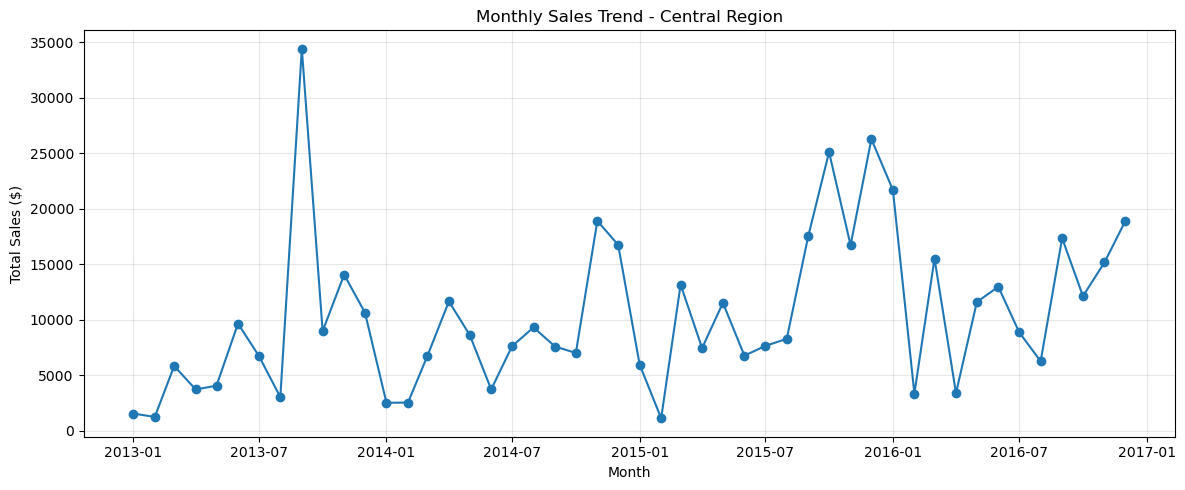

In [73]:
import os
os.makedirs('../outputs/charts', exist_ok=True)

# ---- Chart 1: Monthly Sales Trend ----
df_monthly['Period'] = pd.to_datetime(df_monthly['Year'].astype(str) + '-' + df_monthly['Month'].astype(str) + '-01')

plt.figure(figsize=(12, 5))
plt.plot(df_monthly['Period'], df_monthly['TotalSales'], marker='o', linewidth=1.5)
plt.title('Monthly Sales Trend - Central Region')
plt.xlabel('Month')
plt.ylabel('Total Sales ($)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../outputs/charts/01_monthly_sales_trend.png', dpi=100)
plt.show()


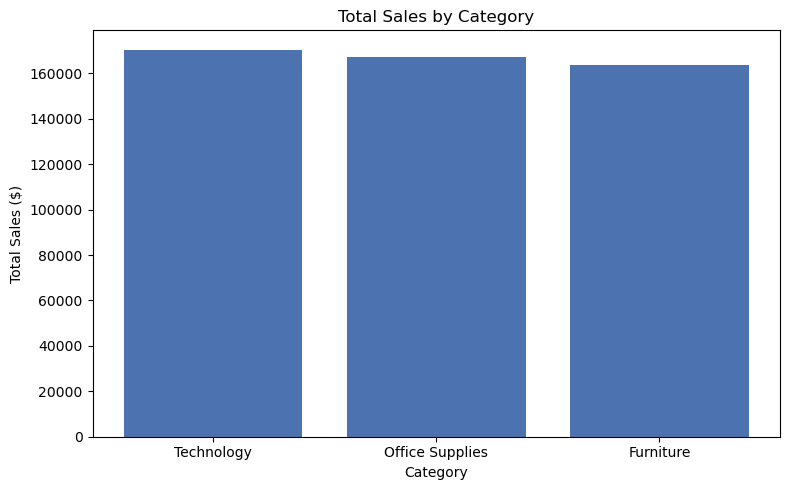

In [74]:
# ---- Chart 2: Sales by Category ----
plt.figure(figsize=(8, 5))
plt.bar(df_category['Category'], df_category['TotalSales'], color='#4C72B0')
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales ($)')
plt.tight_layout()
plt.savefig('../outputs/charts/02_sales_by_category.png', dpi=100)
plt.show()


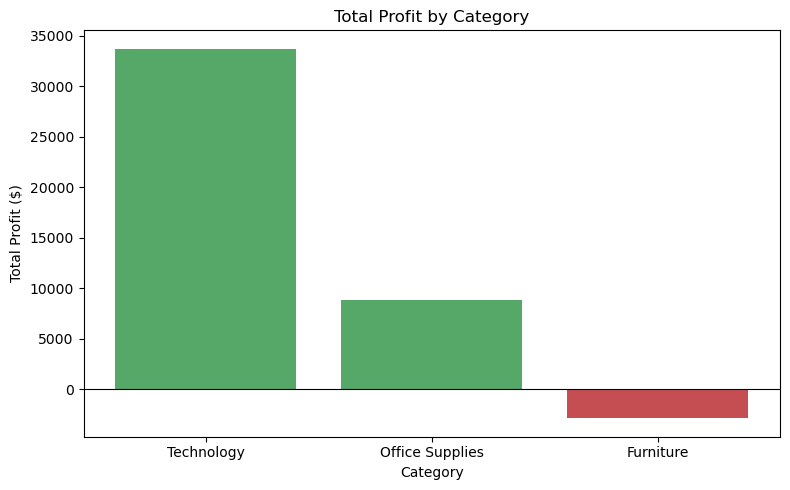

In [75]:
# ---- Chart 3: Profit by Category ----
colors = ['#55A868' if p >= 0 else '#C44E52' for p in df_category['TotalProfit']]
plt.figure(figsize=(8, 5))
plt.bar(df_category['Category'], df_category['TotalProfit'], color=colors)
plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit ($)')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('../outputs/charts/03_profit_by_category.png', dpi=100)
plt.show()


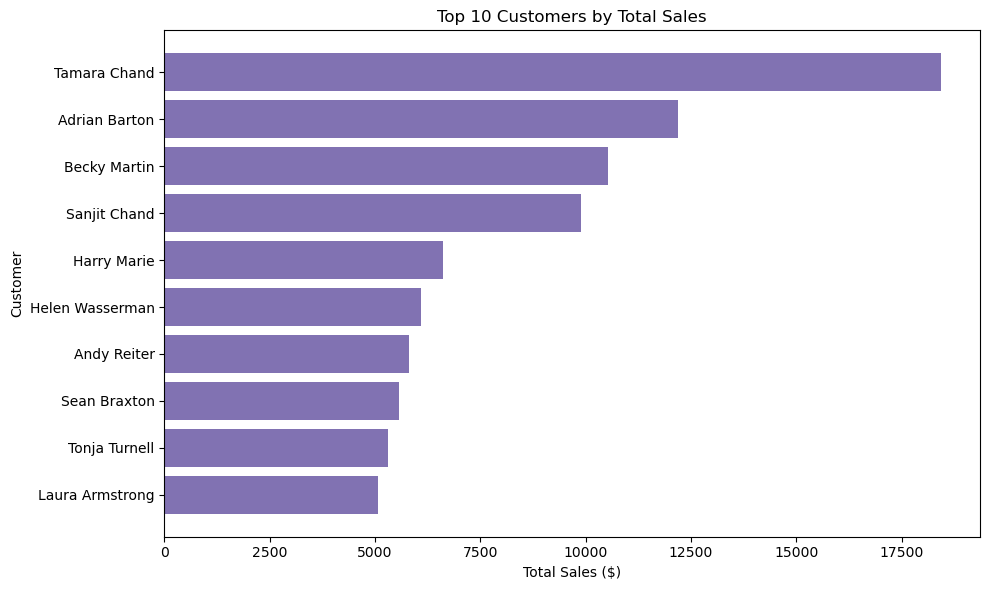

In [76]:
# ---- Chart 4: Top 10 Customers by Sales ----
plt.figure(figsize=(10, 6))
plt.barh(df_top_customers['CustomerName'][::-1], df_top_customers['TotalSales'][::-1], color='#8172B2')
plt.title('Top 10 Customers by Total Sales')
plt.xlabel('Total Sales ($)')
plt.ylabel('Customer')
plt.tight_layout()
plt.savefig('../outputs/charts/04_top10_customers.png', dpi=100)
plt.show()


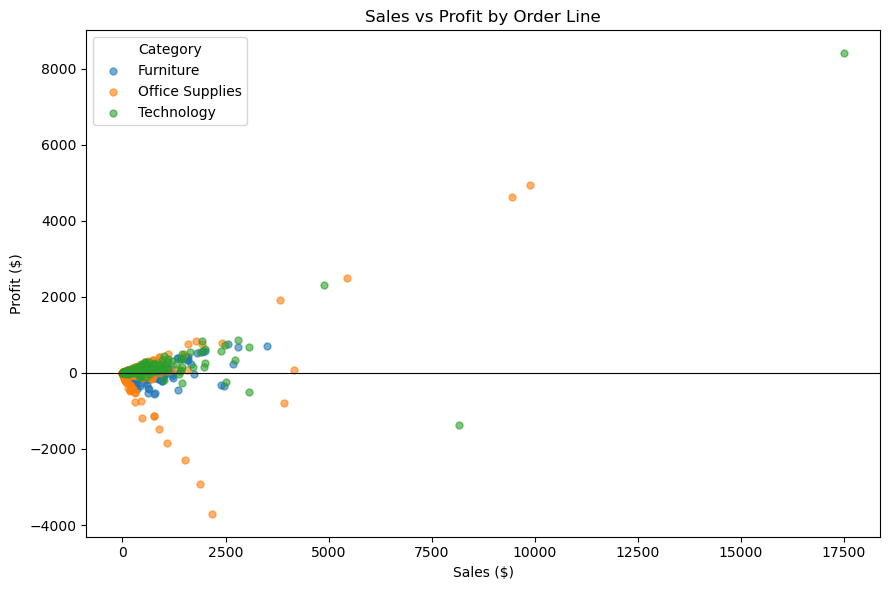

In [77]:
# ---- Chart 5: Sales vs Profit (scatter, colored by Category) ----
plt.figure(figsize=(9, 6))
for cat, group in df_sales_profit.groupby('Category'):
    plt.scatter(group['Sales'], group['Profit'], label=cat, alpha=0.6, s=25)
plt.title('Sales vs Profit by Order Line')
plt.xlabel('Sales ($)')
plt.ylabel('Profit ($)')
plt.axhline(0, color='black', linewidth=0.8)
plt.legend(title='Category')
plt.tight_layout()
plt.savefig('../outputs/charts/05_sales_vs_profit.png', dpi=100)
plt.show()


## 9. KPI Summary (queried from SQL Server)

Recomputing the executive KPI set directly from SQL Server for a final
sanity check.

In [78]:
kpi_query = """
SELECT
    SUM(f.Sales)                              AS TotalSales,
    SUM(f.Profit)                             AS TotalProfit,
    SUM(f.Profit) / NULLIF(SUM(f.Sales), 0)   AS ProfitMarginPct,
    COUNT(DISTINCT f.OrderID)                 AS TotalOrders,
    COUNT(DISTINCT c.CustomerKey)             AS TotalCustomers,
    SUM(f.Quantity)                           AS TotalQuantitySold,
    SUM(f.Sales) / COUNT(DISTINCT f.OrderID)  AS AvgOrderValue,
    SUM(f.Sales) / COUNT(DISTINCT c.CustomerKey) AS AvgSalesPerCustomer,
    SUM(f.Profit) / COUNT(DISTINCT f.OrderID) AS AvgProfitPerOrder
FROM FactSales f
JOIN DimCustomer c ON f.CustomerKey = c.CustomerKey;
"""

df_kpi = pd.read_sql(kpi_query, engine)
df_kpi.T.rename(columns={0: 'Value'})


,Value
TotalSales,501239.890800
TotalProfit,39706.362500
ProfitMarginPct,0.079216
TotalOrders,1175.000000
TotalCustomers,629.000000
TotalQuantitySold,8780.000000
AvgOrderValue,426.587141
AvgSalesPerCustomer,796.883769
AvgProfitPerOrder,33.792648


## 10. Conclusion

This notebook took `Central_Superstore.xlsx`, cleaned it, transformed it into
a 5-dimension + 1-fact Star Schema, loaded it into SQL Server
(`DEPI_Superstore_DW`), and then queried SQL Server directly from Python to
produce KPI summaries and 5 charts — confirming the full Jupyter ↔ SQL
Server ↔ pandas round trip requested by the project brief.

See `docs/Project_Report.md` for the full write-up of findings, and
`sql/05_analytical_queries.sql` for 30 additional analytical queries run
directly in SSMS.
